# Graphite Labeling — Binary Masks for Deep Learning

This notebook uses the adaptive threshold method from Project 1 to produce
binary label images for training a deep learning model.

- **Label 0**: Graphite background (substrate)
- **Label 1**: Features (nanoparticles + support)

For each `.dm3` TEM image, the pipeline:
1. Loads and normalizes the image
2. Applies Gaussian blur
3. Runs adaptive thresholding to separate background from features
4. Saves the processed grayscale image and its binary label as `.tif` files
   in the same labeling folder

In [1]:
import os
from pathlib import Path
import importlib
import numpy as np
import matplotlib.pyplot as plt
import tifffile

# Force reload to pick up any module changes without restarting the kernel
import SELENAtools as st
importlib.reload(st.segment)
importlib.reload(st.histogram)
importlib.reload(st.labels)
importlib.reload(st.image)
importlib.reload(st)

%matplotlib inline

## 1. Configuration

Set the data root path, the folder containing `.dm3` images, and the output
labeling folder.

In [2]:
# Data root — matches config.json
root_path = Path(r'C:\Users\Axel\Nextcloud2\dataProcessing\DeepLearning\2026-09_SELENA')

# Folder containing the .dm3 TEM images to label
# Adjust to point at your graphite-supported sample data
sample_folder = root_path / r'AuCu%grid\SS57-d800'

# Output folder for saved grayscale images and labels
labeling_folder = sample_folder / 'trainingData'
labeling_folder.mkdir(parents=True, exist_ok=True)

## 2. Discover Images

Find all `.dm3` files in the sample folder.

In [3]:
dm3_files = st.find_dm3_files(str(sample_folder), pattern='60kX')
print(f'Found {len(dm3_files)} .dm3 files:')
for f in dm3_files:
    print(f'  {os.path.basename(f)}')

Found 8 .dm3 files:
  60kX-SS57-D800-0007.dm3
  60kX-SS57-D800-0008.dm3
  60kX-SS57-D800-0009.dm3
  60kX-SS57-D800-0010.dm3
  60kX-SS57-D800-0011.dm3
  60kX-SS57-D800-0012.dm3
  60kX-SS57-D800-0013.dm3
  60kX-SS57-D800-0014.dm3


## 3. Parameter Sweep — Compare Multiple Settings

This cell tries several combinations of blur, block_size, offset, and thresholding 
methods side-by-side so you can visually pick the best one. It also applies 
morphological cleanup to reduce speckle noise.

Make sure to run Section 2 (Discover Images) first so `dm3_files` is available.
Then update the parameters in Section 4 with your choice.

Sweeping parameters on: 60kX-SS57-D800-0007.dm3


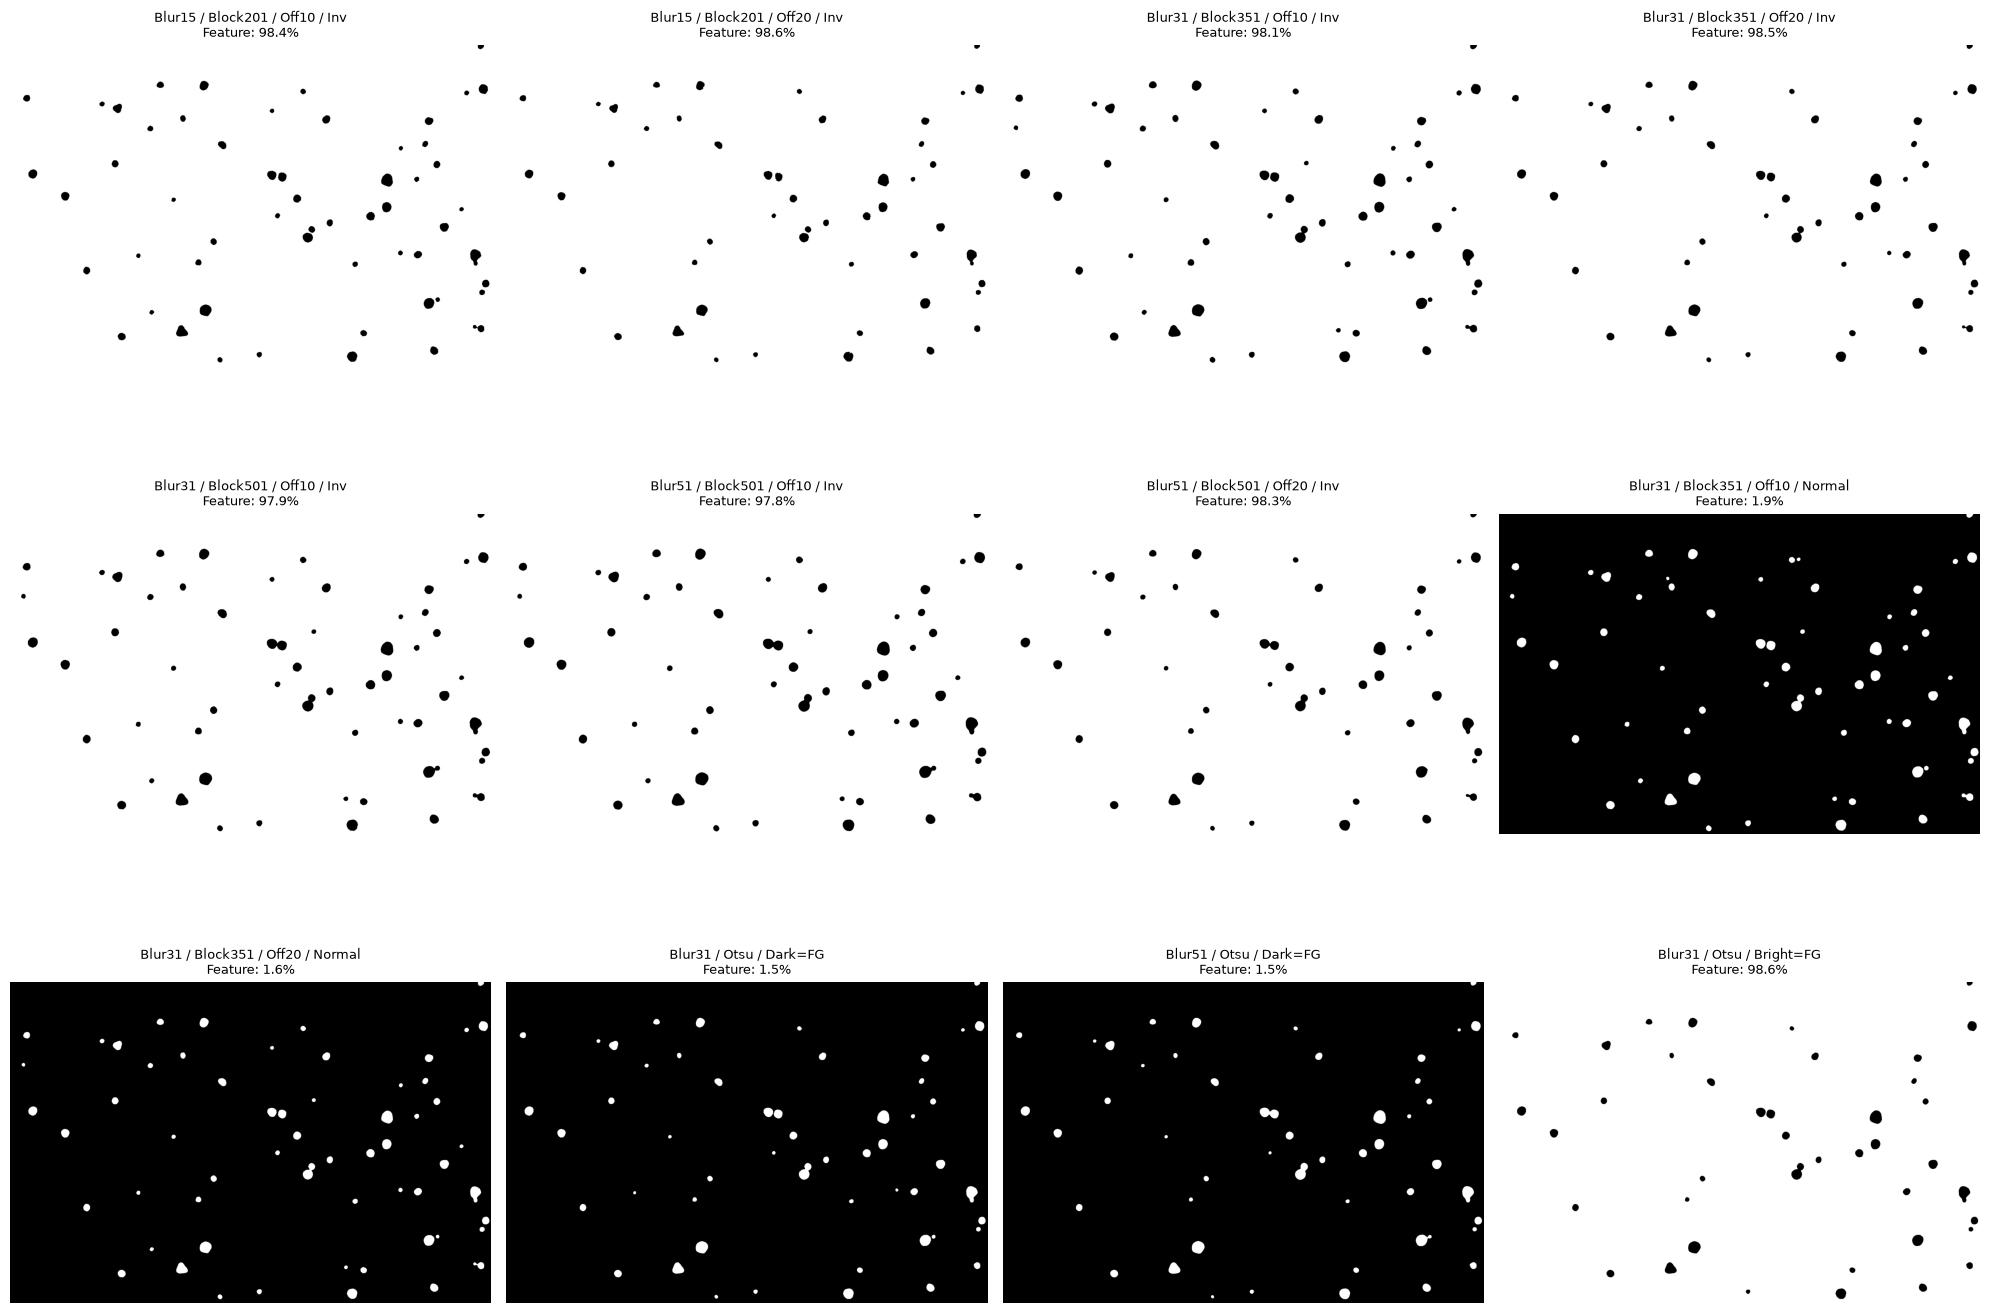


Tip: Pick the panel that best outlines the support material,
then update the parameters in Section 4 with your choice.
Key: Inv=THRESH_BINARY_INV (dark=feature), Normal=THRESH_BINARY (bright=feature)


In [4]:
if len(dm3_files) == 0:
    raise FileNotFoundError('No .dm3 files found. Check your sample_folder path.')

preview_path = dm3_files[0]
print(f'Sweeping parameters on: {os.path.basename(preview_path)}')

# Load and normalize once
image, metadata = st.load_tem_image(preview_path)

# Define parameter combinations to try
param_grid = [
    # (blur_kernel, block_size, offset, method, label)
    (15, 201, 10, 'adaptive_inv', 'Blur15 / Block201 / Off10 / Inv'),
    (15, 201, 20, 'adaptive_inv', 'Blur15 / Block201 / Off20 / Inv'),
    (31, 351, 10, 'adaptive_inv', 'Blur31 / Block351 / Off10 / Inv'),
    (31, 351, 20, 'adaptive_inv', 'Blur31 / Block351 / Off20 / Inv'),
    (31, 501, 10, 'adaptive_inv', 'Blur31 / Block501 / Off10 / Inv'),
    (51, 501, 10, 'adaptive_inv', 'Blur51 / Block501 / Off10 / Inv'),
    (51, 501, 20, 'adaptive_inv', 'Blur51 / Block501 / Off20 / Inv'),
    (31, 351, 10, 'adaptive', 'Blur31 / Block351 / Off10 / Normal'),
    (31, 351, 20, 'adaptive', 'Blur31 / Block351 / Off20 / Normal'),
    (31, 0, 0, 'otsu', 'Blur31 / Otsu / Dark=FG'),
    (51, 0, 0, 'otsu', 'Blur51 / Otsu / Dark=FG'),
    (31, 0, 0, 'otsu_bright', 'Blur31 / Otsu / Bright=FG'),
]

n = len(param_grid)
cols = 4
rows = (n + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(20, 5 * rows))
axes = axes.flatten()

for idx, (blur_k, blk_sz, off, method, label) in enumerate(param_grid):
    ax = axes[idx]
    
    # Apply blur
    blurred = st.apply_gaussian_blur(image, kernel_size=blur_k)
    
    # Apply thresholding method
    if method == 'adaptive_inv':
        binary = st.adaptive_threshold_inv(blurred, block_size=blk_sz, offset=off)
    elif method == 'adaptive':
        binary = st.adaptive_threshold(blurred, block_size=blk_sz, offset=off)
    elif method == 'otsu':
        binary = st.global_threshold(blurred, invert=True)
    elif method == 'otsu_bright':
        binary = st.global_threshold(blurred, invert=False)
    
    # Apply morphological cleanup to reduce speckle
    cleaned = st.cleanup_mask(binary, min_object_area=500, max_hole_area=1000)
    
    # Compute feature percentage
    fg_pct = 100 * np.sum(cleaned > 0) / cleaned.size
    
    ax.imshow(cleaned, cmap='gray')
    ax.set_title(f'{label}\nFeature: {fg_pct:.1f}%', fontsize=9)
    ax.axis('off')

# Hide any unused subplots
for idx in range(len(param_grid), len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

print('\nTip: Pick the panel that best outlines the support material,')
print('then update the parameters in Section 4 with your choice.')
print('Key: Inv=THRESH_BINARY_INV (dark=feature), Normal=THRESH_BINARY (bright=feature)')

## 4. Selected Parameters

After reviewing the parameter sweep, set the chosen segmentation method.
This section locks in the parameters for Preview and Batch processing.

In [5]:
#31, 351, 10, 'adaptive', 'Blur31 / Block351 / Off10 / Normal'
# Chosen from parameter sweep: Blur51 / Otsu / Dark=FG
blur_kernel = 31        # Gaussian blur kernel size
threshold_method = 'adaptive'  # Options: "otsu", "adaptive", "adaptive_inv"

# Adaptive threshold params (only used if threshold_method is adaptive)
block_size = 351       # Adaptive threshold block size
offset = 10            # Offset subtracted from the local mean

# Morphological cleanup params
min_object_area = 500  # Minimum area in pixels to keep an object
max_hole_area = 1000   # Maximum hole area to fill inside objects

print("Selected: Blur" + str(blur_kernel) + " / " + threshold_method.upper() + " / Dark=FG")
print("Cleanup: min_object=" + str(min_object_area) + ", max_hole=" + str(max_hole_area))

Selected: Blur31 / ADAPTIVE / Dark=FG
Cleanup: min_object=500, max_hole=1000


## 5. Preview on a Single Image

Preview the segmentation result using the selected parameters on one image
to verify quality before batch processing.

Preview: 60kX-SS57-D800-0007.dm3


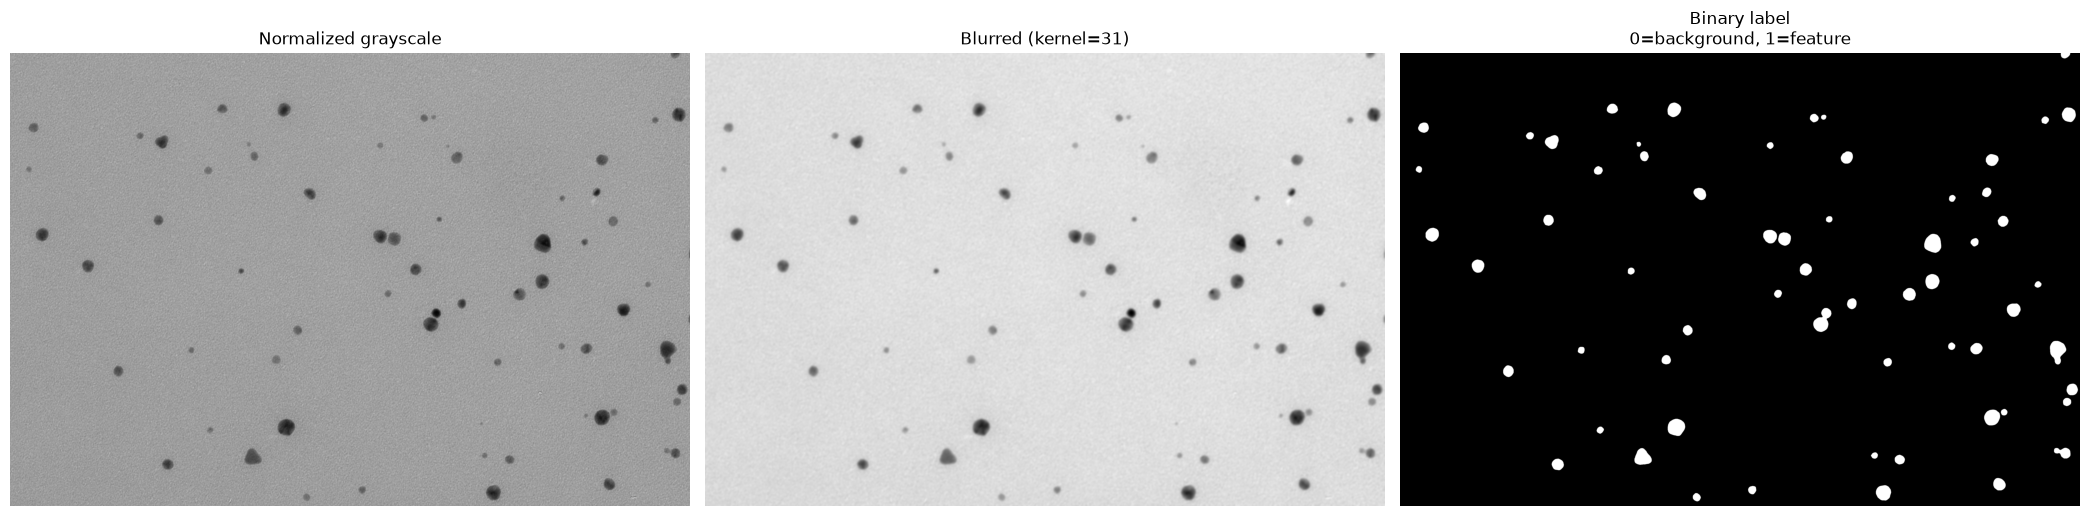

Label shape: (2672, 4008)
Method: adaptive, blur_kernel=31
Background (0): 10504029 pixels (98.1%)
Feature    (1): 205347 pixels (1.9%)


In [6]:
if len(dm3_files) == 0:
    raise FileNotFoundError("No .dm3 files found. Check your sample_folder path.")

# Pick the first image for preview
preview_path = dm3_files[0]
print("Preview: " + os.path.basename(preview_path))

# Pipeline: load -> normalize -> blur -> threshold -> cleanup
image, metadata = st.load_tem_image(preview_path)
blurred = st.apply_gaussian_blur(image, kernel_size=blur_kernel)

# Apply selected thresholding method
if threshold_method == "otsu":
    binary_mask = st.global_threshold(blurred, invert=True)
elif threshold_method == "adaptive_inv":
    binary_mask = st.adaptive_threshold_inv(blurred, block_size=block_size, offset=offset)
elif threshold_method == "adaptive":
    binary_mask = st.adaptive_threshold(blurred, block_size=block_size, offset=offset)

# Morphological cleanup to remove speckle noise
cleaned = st.cleanup_mask(binary_mask, min_object_area=min_object_area, max_hole_area=max_hole_area)

# Convert binary mask to label: 0 = background, 1 = feature
label = (cleaned > 0).astype(np.uint8)

# Visualize
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
axes[0].imshow(image, cmap="gray")
axes[0].set_title("Normalized grayscale")
axes[0].axis("off")

axes[1].imshow(blurred, cmap="gray")
axes[1].set_title("Blurred (kernel=" + str(blur_kernel) + ")")
axes[1].axis("off")

axes[2].imshow(label, cmap="gray")
axes[2].set_title("Binary label\n0=background, 1=feature")
axes[2].axis("off")

plt.tight_layout()
plt.show()

# Print label statistics
bg_count = np.sum(label == 0)
fg_count = np.sum(label == 1)
total = bg_count + fg_count
print("Label shape: " + str(label.shape))
print("Method: " + threshold_method + ", blur_kernel=" + str(blur_kernel))
bg_pct = 100 * bg_count / total
fg_pct = 100 * fg_count / total
print("Background (0): " + str(bg_count) + " pixels (" + str(round(bg_pct, 1)) + "%)")
print("Feature    (1): " + str(fg_count) + " pixels (" + str(round(fg_pct, 1)) + "%)")

## 6. Batch Process All Images

Once you are satisfied with the preview, run this cell to process all images
and save the results using the selected parameters.

In [7]:
saved_count = 0

for dm3_path in dm3_files:
    dm3_basename = os.path.basename(dm3_path)
    stem = os.path.splitext(dm3_basename)[0]
    print("Processing: " + dm3_basename)

    # Step 1: Load & normalize
    image, metadata = st.load_tem_image(dm3_path)

    # Step 2: Gaussian blur
    blurred = st.apply_gaussian_blur(image, kernel_size=blur_kernel)

    # Step 3: Apply selected thresholding method
    if threshold_method == "otsu":
        binary_mask = st.global_threshold(blurred, invert=True)
    elif threshold_method == "adaptive_inv":
        binary_mask = st.adaptive_threshold_inv(blurred, block_size=block_size, offset=offset)
    elif threshold_method == "adaptive":
        binary_mask = st.adaptive_threshold(blurred, block_size=block_size, offset=offset)

    # Step 3b: Morphological cleanup to remove speckle noise
    cleaned = st.cleanup_mask(binary_mask, min_object_area=min_object_area, max_hole_area=max_hole_area)
    label = (cleaned > 0).astype(np.uint8)

    # Step 4: Save grayscale image and label as .tif
    img_out = labeling_folder / (stem + ".tif")
    lab_out = labeling_folder / (stem + "_lab.tif")

    tifffile.imwrite(str(img_out), blurred)
    tifffile.imwrite(str(lab_out), label)

    saved_count += 1
    print("  -> Saved: " + img_out.name + ", " + lab_out.name)

print("")
print("Done! Saved " + str(saved_count) + " image-label pairs to:")
print("  " + str(labeling_folder))

Processing: 60kX-SS57-D800-0007.dm3
  -> Saved: 60kX-SS57-D800-0007.tif, 60kX-SS57-D800-0007_lab.tif
Processing: 60kX-SS57-D800-0008.dm3
  -> Saved: 60kX-SS57-D800-0008.tif, 60kX-SS57-D800-0008_lab.tif
Processing: 60kX-SS57-D800-0009.dm3
  -> Saved: 60kX-SS57-D800-0009.tif, 60kX-SS57-D800-0009_lab.tif
Processing: 60kX-SS57-D800-0010.dm3
  -> Saved: 60kX-SS57-D800-0010.tif, 60kX-SS57-D800-0010_lab.tif
Processing: 60kX-SS57-D800-0011.dm3
  -> Saved: 60kX-SS57-D800-0011.tif, 60kX-SS57-D800-0011_lab.tif
Processing: 60kX-SS57-D800-0012.dm3
  -> Saved: 60kX-SS57-D800-0012.tif, 60kX-SS57-D800-0012_lab.tif
Processing: 60kX-SS57-D800-0013.dm3
  -> Saved: 60kX-SS57-D800-0013.tif, 60kX-SS57-D800-0013_lab.tif
Processing: 60kX-SS57-D800-0014.dm3
  -> Saved: 60kX-SS57-D800-0014.tif, 60kX-SS57-D800-0014_lab.tif

Done! Saved 8 image-label pairs to:
  C:\Users\Axel\Nextcloud2\dataProcessing\DeepLearning\2026-09_SELENA\AuCu%grid\SS57-d800\trainingData


## 7. Verify Saved Labels

Quickly check that the saved label files have the expected classes.

In [ ]:
label_files = sorted(labeling_folder.glob('*_lab.tif'))
print(f'Found {len(label_files)} label files:')

for lf in label_files:
    arr = tifffile.imread(str(lf))
    unique = np.unique(arr)
    print(f'  {lf.name}: shape={arr.shape}, unique values={unique.tolist()}')